# Phase 1 — Explore the SECOM data

**Goal:** understand the semiconductor data before modeling.

Dataset → Load → Explore → Clean → Visualize

Each row is one wafer: a pass/fail label (`class`), a `timestamp`, and 590 anonymous sensor readings (`Attribute 1` … `Attribute 590`).

## 1. Load

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../data")
RAW_PATH = DATA_DIR / "secom_raw.csv"

# Download the SECOM data from UCI once, then reuse the local copy
data_url = "https://archive.ics.uci.edu/static/public/179/data.csv"

# Creates data file in /data
# df = csv file object
if RAW_PATH.exists():
    df = pd.read_csv(RAW_PATH) #Loads a file into an object
else:
    df = pd.read_csv(data_url) #Loads a file into an object
    df.to_csv(RAW_PATH, index=False) #Loads csv object into path as a new file

df = df.copy()  # consolidate memory so adding columns later doesn't trigger warnings

print(df.shape, "(Rows/ Manufactured wafers, Columns/ label + timestamp + sensor measurements)")

(1567, 592) (Rows/ Manufactured wafers, Columns/ label + timestamp + sensor measurements)


In [ ]:
# .head(n) - First n rows (default 5)
df.head()

,class,timestamp,Attribute 1,Attribute 2,Attribute 3,Attribute 4,Attribute 5,Attribute 6,Attribute 7,Attribute 8,...,Attribute 581,Attribute 582,Attribute 583,Attribute 584,Attribute 585,Attribute 586,Attribute 587,Attribute 588,Attribute 589,Attribute 590
0,-1,19/07/2008 11:55:00,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,...,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,-1,19/07/2008 12:32:00,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,1,19/07/2008 13:17:00,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,-1,19/07/2008 14:43:00,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,-1,19/07/2008 15:22:00,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,...,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432


In [ ]:
# .info() - Column names, non-null counts, datatypes, memory use
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1567 entries, 0 to 1566
Columns: 592 entries, class to Attribute 590
dtypes: float64(590), int64(1), str(1)
memory usage: 7.1 MB


## 2. Explore

### Pass / fail balance
In SECOM, `-1` means the wafer **passed** and `1` means it **failed**. We add a clearer 0/1 `fail` column.

In [7]:
df["fail"] = (df["class"] == 1).astype(int)

counts = df["fail"].value_counts().rename({0: "pass", 1: "fail"})
print(counts)
print(f"\nFail rate: {df['fail'].mean():.1%}")

fail
pass    1463
fail     104
Name: count, dtype: int64

Fail rate: 6.6%


Only about 1 in 15 wafers fails, so the classes are **heavily imbalanced**. A model that always predicts "pass" would be ~93% accurate and completely useless, so in Phase 2 we should judge models on fail recall, precision, F1, or ROC-AUC rather than plain accuracy.

### Timestamps

In [8]:
# Dates are day-first (DD/MM/YYYY), and some rows omit seconds or leading zeros
df["timestamp"] = pd.to_datetime(df["timestamp"], format="mixed", dayfirst=True)

print("First wafer:", df["timestamp"].min())
print("Last wafer: ", df["timestamp"].max())
print("Span:       ", df["timestamp"].max() - df["timestamp"].min())

First wafer: 2008-07-19 11:55:00
Last wafer:  2008-10-17 06:07:00
Span:        89 days 18:12:00


### Sensor summary statistics

In [9]:
sensor_cols = [c for c in df.columns if c.startswith("Attribute")]
print(len(sensor_cols), "sensor columns")

df[sensor_cols].describe().T.head(15)

590 sensor columns


,count,mean,std,min,25%,50%,75%,max
Attribute 1,1561.0,3014.452896,73.621787,2743.2400,2966.260000,3011.4900,3056.650000,3356.3500
Attribute 2,1560.0,2495.850231,80.407705,2158.7500,2452.247500,2499.4050,2538.822500,2846.4400
Attribute 3,1553.0,2200.547318,29.513152,2060.6600,2181.044400,2201.0667,2218.055500,2315.2667
Attribute 4,1553.0,1396.376627,441.691640,0.0000,1081.875800,1285.2144,1591.223500,3715.0417
Attribute 5,1553.0,4.197013,56.355540,0.6815,1.017700,1.3168,1.525700,1114.5366
Attribute 6,1553.0,100.000000,0.000000,100.0000,100.000000,100.0000,100.000000,100.0000
Attribute 7,1553.0,101.112908,6.237214,82.1311,97.920000,101.5122,104.586700,129.2522
Attribute 8,1558.0,0.121822,0.008961,0.0000,0.121100,0.1224,0.123800,0.1286
Attribute 9,1565.0,1.462862,0.073897,1.1910,1.411200,1.4616,1.516900,1.6564
Attribute 10,1565.0,-0.000841,0.015116,-0.0534,-0.010800,-0.0013,0.008400,0.0749


The sensors are on very different scales (some in the thousands, some below 1), so they will need scaling before models like logistic regression.

### Missing values

In [10]:
missing_frac = df[sensor_cols].isna().mean().sort_values(ascending=False)

print("Total missing cells:     ", df[sensor_cols].isna().sum().sum())
print("Sensors with any missing:", (missing_frac > 0).sum())
print("Sensors >50% missing:    ", (missing_frac > 0.5).sum())

missing_frac.head(10)

Total missing cells:      41951
Sensors with any missing: 538
Sensors >50% missing:     28


Attribute 293    0.911934
Attribute 294    0.911934
Attribute 159    0.911934
Attribute 158    0.911934
Attribute 493    0.855775
Attribute 86     0.855775
Attribute 359    0.855775
Attribute 221    0.855775
Attribute 245    0.649649
Attribute 518    0.649649
dtype: float64

### Constant sensors
A sensor that reports the same value for every wafer carries no information.

In [11]:
n_unique = df[sensor_cols].nunique()
constant_cols = n_unique[n_unique <= 1].index.tolist()
print(len(constant_cols), "constant sensors")

116 constant sensors


## 3. Visualize

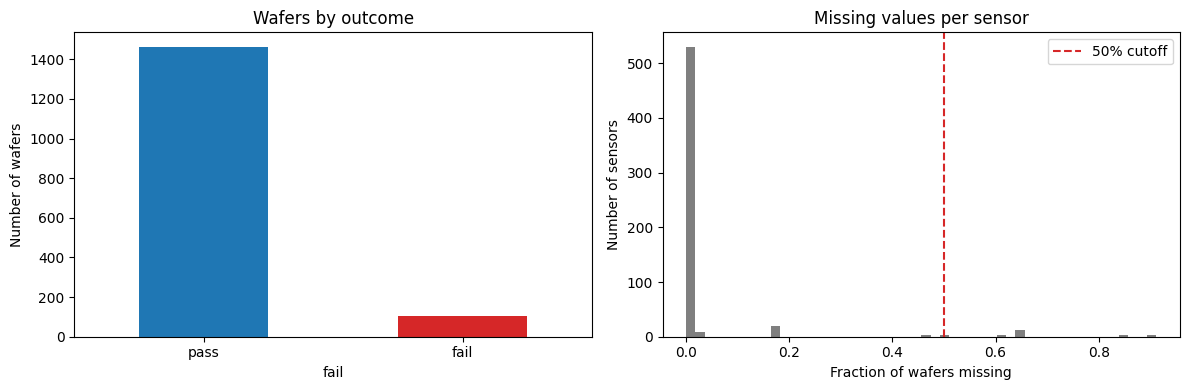

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Class balance
counts.plot.bar(ax=axes[0], color=["tab:blue", "tab:red"], rot=0)
axes[0].set_title("Wafers by outcome")
axes[0].set_ylabel("Number of wafers")

# How much of each sensor is missing
axes[1].hist(missing_frac, bins=50, color="tab:gray")
axes[1].axvline(0.5, color="tab:red", linestyle="--", label="50% cutoff")
axes[1].set_title("Missing values per sensor")
axes[1].set_xlabel("Fraction of wafers missing")
axes[1].set_ylabel("Number of sensors")
axes[1].legend()

plt.tight_layout()
plt.show()

### Failures over time
If failures cluster in certain weeks, the process may have drifted (a useful hint for Phase 4, anomaly detection).

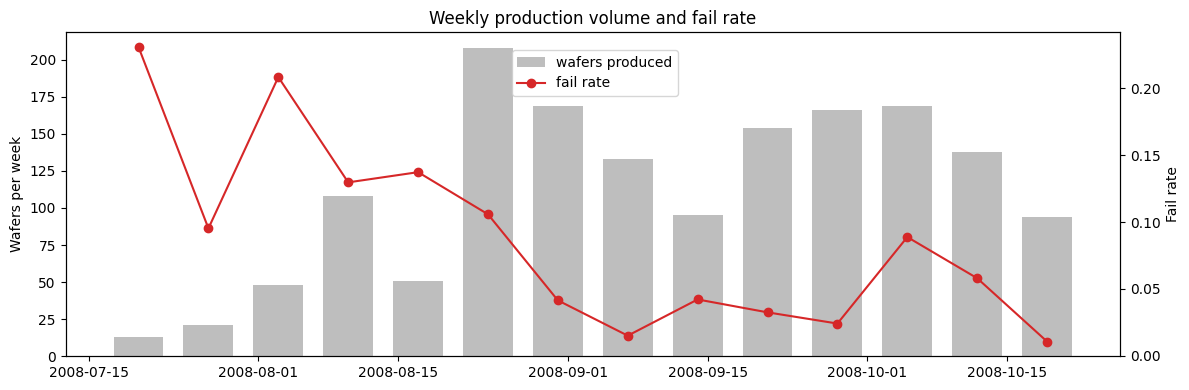

In [13]:
weekly = df.set_index("timestamp").resample("W")["fail"].agg(["count", "mean"])

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.bar(weekly.index, weekly["count"], width=5, color="tab:gray", alpha=0.5, label="wafers produced")
ax1.set_ylabel("Wafers per week")

ax2 = ax1.twinx()
ax2.plot(weekly.index, weekly["mean"], color="tab:red", marker="o", label="fail rate")
ax2.set_ylabel("Fail rate")

ax1.set_title("Weekly production volume and fail rate")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.88))
plt.tight_layout()
plt.show()

## 4. Clean

Cleaning steps:
1. Drop sensors that are **more than 50% missing**. Too little data to trust.
2. Drop **constant** sensors. No information.
3. Drop the original `class` column (replaced by `fail`).

We do **not** fill in (impute) the remaining missing values here. Imputation and scaling should be learned from the training data only, inside the Phase 2 model pipeline, otherwise information from the test set leaks into training.

In [14]:
high_missing_cols = missing_frac[missing_frac > 0.5].index.tolist()
drop_cols = sorted(set(high_missing_cols) | set(constant_cols), key=sensor_cols.index)

clean = df.drop(columns=drop_cols + ["class"])
kept_sensors = [c for c in clean.columns if c.startswith("Attribute")]

print(f"Dropped {len(high_missing_cols)} high-missing + {len(constant_cols)} constant "
      f"= {len(drop_cols)} sensors")
print(f"Kept {len(kept_sensors)} of {len(sensor_cols)} sensors")
print(f"Remaining missing cells: {clean[kept_sensors].isna().sum().sum()} "
      f"({clean[kept_sensors].isna().mean().mean():.1%} of sensor values)")

Dropped 28 high-missing + 116 constant = 144 sensors
Kept 446 of 590 sensors
Remaining missing cells: 10868 (1.6% of sensor values)


## 5. Which sensors differ between pass and fail?

A first look at which sensors might matter. For each sensor we compare the pass and fail groups using the difference in medians, divided by the sensor's overall spread (so sensors on different scales are comparable). Medians are used because many sensors have extreme outliers.

In [15]:
pass_med = clean.loc[clean["fail"] == 0, kept_sensors].median()
fail_med = clean.loc[clean["fail"] == 1, kept_sensors].median()
spread = clean[kept_sensors].std()

effect = ((fail_med - pass_med) / spread).dropna()
top_sensors = effect.abs().sort_values(ascending=False).head(10).index

effect[top_sensors].round(3)

Attribute 96     0.958
Attribute 512    0.845
Attribute 104    0.653
Attribute 60     0.504
Attribute 125    0.482
Attribute 456    0.454
Attribute 59     0.451
Attribute 184    0.432
Attribute 123   -0.394
Attribute 138    0.381
dtype: float64

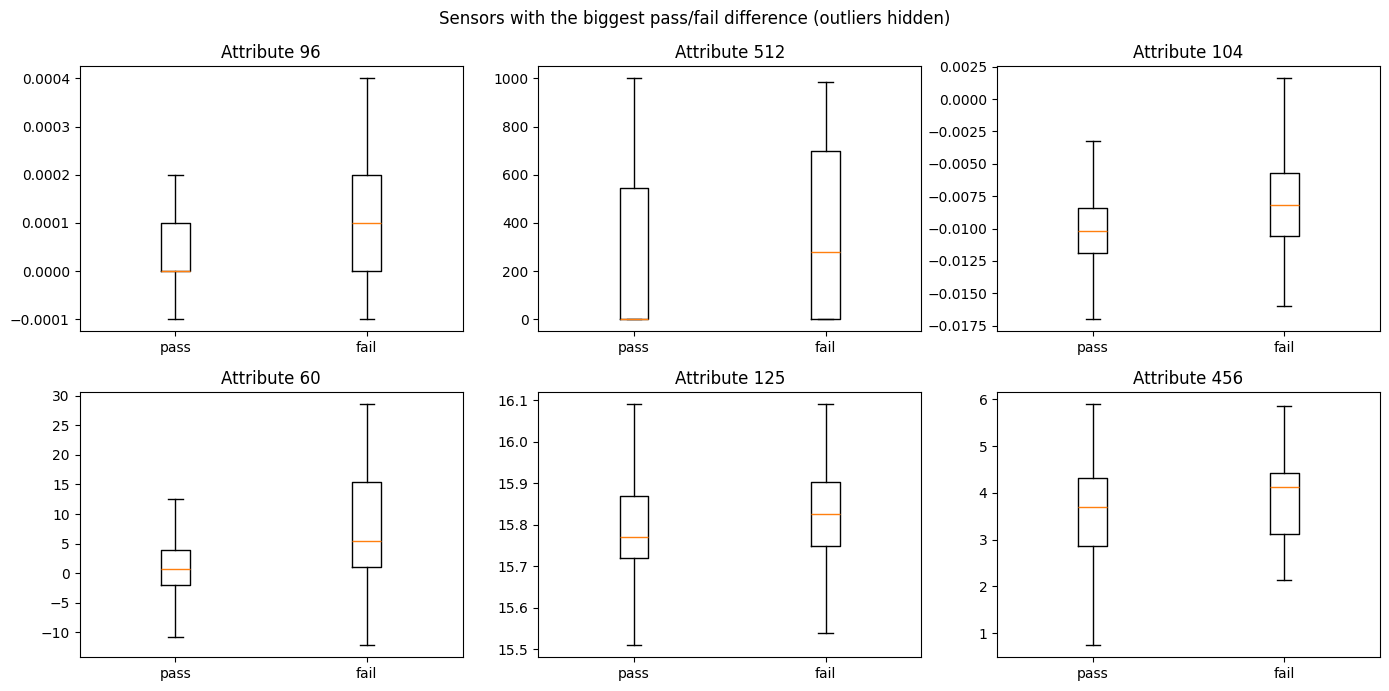

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for ax, col in zip(axes.flat, top_sensors[:6]):
    data = [clean.loc[clean["fail"] == 0, col].dropna(),
            clean.loc[clean["fail"] == 1, col].dropna()]
    ax.boxplot(data, tick_labels=["pass", "fail"], showfliers=False)
    ax.set_title(col)

fig.suptitle("Sensors with the biggest pass/fail difference (outliers hidden)")
plt.tight_layout()
plt.show()

### How correlated are the sensors?
Many sensors likely measure related things. Strong correlation means there is redundant information we can trim in Phase 3.

Sensor pairs with |correlation| > 0.95: 272


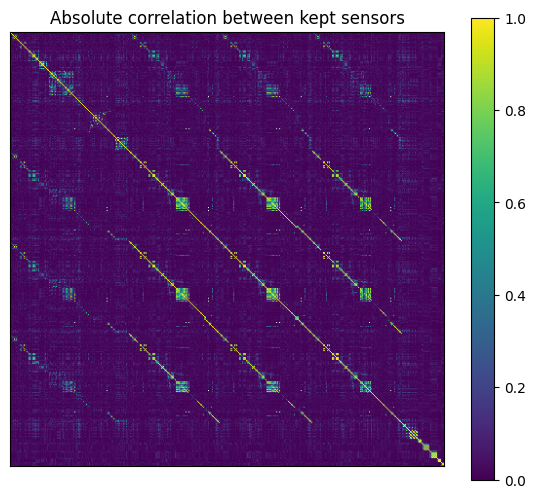

In [17]:
corr = clean[kept_sensors].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))

print("Sensor pairs with |correlation| > 0.95:", int((upper > 0.95).sum().sum()))

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="viridis", vmin=0, vmax=1)
ax.set_title("Absolute correlation between kept sensors")
ax.set_xticks([])
ax.set_yticks([])
fig.colorbar(im, ax=ax)
plt.show()

## 6. Save the cleaned data for Phase 2

In [18]:
CLEAN_PATH = DATA_DIR / "secom_clean.csv"
clean.to_csv(CLEAN_PATH, index=False)
print("Saved", clean.shape, "to", CLEAN_PATH)

Saved (1567, 448) to ..\data\secom_clean.csv


## Phase 1 takeaways

- **1,567 wafers, 590 sensors**, collected July–October 2008.
- **Heavily imbalanced:** only ~6.6% of wafers fail. Use recall, F1, or ROC-AUC, not accuracy, and consider class weights.
- **Messy sensors:** most sensors have some missing values, and a few are mostly empty. Many are constant. After cleaning, we keep the remaining sensors in `data/secom_clean.csv`.
- **Scales vary wildly**, so standardize features for linear models.
- **Failures were not steady over time:** the weekly fail rate was much higher in July–August than in September–October. That could be process drift or early ramp-up, and it matters for Phase 4 (anomaly detection). It also means a time-based train/test split is a tougher, more realistic test than a random one.
- **Lots of redundancy** between sensors, which is a good target for feature selection in Phase 3.
- **Next (Phase 2):** split train/test (stratified by `fail`), then a pipeline of median imputation → scaling → simple classifier (e.g. logistic regression with `class_weight="balanced"`).